In [71]:
import numpy as np
import pandas as pd

In [72]:
#upload data intended for use
df=pd.read_csv('/content/Filtered maternity Register - Filtered maternity Register.csv')

In [73]:
headers = df.columns.values.tolist()
print(headers)

['start', 'end', 'start-geopoint', '_start-geopoint_latitude', '_start-geopoint_longitude', '_start-geopoint_altitude', '_start-geopoint_precision', 'County', 'Sub County (Kisumu)', 'Sub County (Siaya)', 'Facility Name (Nyando)', 'Facility Name (Seme)', 'Facility Name (Nyakach)', 'Facility Name (Kisumu Central)/Kisumu County Referral Hospital - #13704', 'Facility Name (Kisumu West)', 'Facility Name (Kisumu East)', 'Facility Name (Alego-Usonga)', 'Facility Name (Gem)', 'Facility Name (Ugunja)', 'Facility Type', 'Date of Data Extraction', 'Extracted by', 'Admission date', 'Admission  no.', 'DoB/age', 'Sub-county', 'Village/estate', 'Marital Status', 'Parity', 'Gravidae', 'ANC visits', 'LMP', 'EDD', 'Diagnosis', 'Diagnosis Conclusion (Referred or Not/False  Labour)', 'Labour', 'Delivery date', 'Time of delivery', 'Gestation', 'Delivery mode', 'No. of babies', 'Mother status', 'Mother died', 'Complications', 'Babies born', 'Birth outcome 1', 'Birth weight 1', 'Baby’s sex 1', 'Birth outcome

In [74]:
df.describe()

,_start-geopoint_latitude,_start-geopoint_longitude,_start-geopoint_altitude,_start-geopoint_precision,Sub County (Siaya),Facility Name (Nyando),Facility Name (Seme),Facility Name (Nyakach),Facility Name (Kisumu Central)/Kisumu County Referral Hospital - #13704,Facility Name (Kisumu East),...,Discharge baby 5,Village/estate. (Use the code 'MD' for Missing data or 'NIR' for Not in the register as a response to this question if needed.),Parity (Use the code 'MD' for Missing data or 'NIR' for Not in the register as a response to this question if needed.),Diagnosis (Detailed),Remarks,_id,_validation_status,_notes,_tags,_index
count,4799.000000,4799.000000,4799.000000,4799.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,5.993000e+03,0.0,0.0,0.0,5993.000000
mean,-0.060132,34.640811,1161.592174,285.673453,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.729180e+08,NaN,NaN,NaN,29375.963124
std,0.035052,0.032143,434.606170,775.228922,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.002680e+07,NaN,NaN,NaN,9318.034685
min,-0.115462,34.603186,0.000000,1.050000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.559491e+08,NaN,NaN,NaN,8633.000000
25%,-0.114955,34.609559,1221.000000,3.050000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.637380e+08,NaN,NaN,NaN,21874.000000
50%,-0.038012,34.638314,1349.599976,16.118000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.730816e+08,NaN,NaN,NaN,30191.000000
75%,-0.037897,34.638386,1350.099976,25.083000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.797377e+08,NaN,NaN,NaN,36162.000000
max,-0.018568,34.772521,1784.600000,4800.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.956357e+08,NaN,NaN,NaN,47882.000000


In [75]:
#Retain only columns i will need and drop the rest
df_select=df[['Facility Name (Kisumu West)','Admission  no.','Gravidae','Babies born','Birth weight 1','Birth weight 2','Birth weight 3']]
print(df_select)


        Facility Name (Kisumu West) Admission  no. Gravidae  Babies born  \
0     Chulaimbo Sub County Hospital           1234        2            2   
1     Chulaimbo Sub County Hospital            637        6            1   
2     Chulaimbo Sub County Hospital            644        1            1   
3     Chulaimbo Sub County Hospital            646        3            1   
4     Chulaimbo Sub County Hospital            645        1            1   
...                             ...            ...      ...          ...   
5988  Chulaimbo Sub County Hospital         288/20        2            1   
5989  Chulaimbo Sub County Hospital         289/20        3            1   
5990  Chulaimbo Sub County Hospital         265/20        1            1   
5991  Chulaimbo Sub County Hospital         290/20        4            1   
5992  Chulaimbo Sub County Hospital         291/20        3            1   

      Birth weight 1  Birth weight 2  Birth weight 3  
0                2.5            

In [76]:
#total number of missing gravidae entries
df_select['Gravidae'].isna().sum()

np.int64(0)

In [77]:
#drop rows in gravidae with missing values
df_select = df_select.dropna(subset=['Gravidae'])

In [78]:
# Ensuring all gravidae are integers
#1st transform to numeric
df_select["Gravidae"] = pd.to_numeric(df_select["Gravidae"], errors="coerce")

# Remove rows where Gravidae could not be converted to a number
df_select = df_select.dropna(subset=["Gravidae"])

# Convert to integer
df_select["Gravidae"] = df_select["Gravidae"].astype(int)

In [79]:
#drop rows with missing values for babies born
df_select=df_select.dropna(subset=['Babies born'])

In [80]:
#get total number of missing entries in bby born column
df_select['Babies born'].isna().sum()

np.int64(0)

In [81]:
df_select['Birth weight 1'].isna().sum()

np.int64(0)

In [82]:
#detecting and removing outliers
Q1 = df['Birth weight 1'].quantile(0.25)
Q3 = df['Birth weight 1'].quantile(0.75)
IQR = Q3 - Q1

#Define acceptable boundaries

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out the outliers
df_cleaned= df_select[
    (df_select['Birth weight 1'] >= lower_bound) &
    (df_select['Birth weight 1'] <= upper_bound)
]

In [83]:
df_cleaned.describe()

,Gravidae,Babies born,Birth weight 1,Birth weight 2,Birth weight 3
count,5583.000000,5583.000000,5583.000000,40.000000,1.0
mean,2.645173,1.007344,3188.684399,2361.400000,98.0
std,1.662713,0.087461,437.808441,695.763915,NaN
min,1.000000,1.000000,2000.000000,98.000000,98.0
25%,1.000000,1.000000,2950.000000,2100.000000,98.0
50%,2.000000,1.000000,3200.000000,2355.000000,98.0
75%,4.000000,1.000000,3500.000000,2700.000000,98.0
max,33.000000,3.000000,4400.000000,3600.000000,98.0


In [84]:
#list of all columns contained in cleaned dataframe
print(df_cleaned.columns.tolist())

['Facility Name (Kisumu West)', 'Admission  no.', 'Gravidae', 'Babies born', 'Birth weight 1', 'Birth weight 2', 'Birth weight 3']


In [85]:
df_weight = df_cleaned.melt(
    id_vars=['Admission  no.','Gravidae','Babies born'],
    value_vars=['Birth weight 1', 'Birth weight 2', 'Birth weight 3'],
    var_name='Baby_number',
    value_name='Birth_weight'
)

#Get rid of outliers in the new birth eight column birth weights

Q1 = df_weight['Birth_weight'].quantile(0.25)
Q3 = df_weight['Birth_weight'].quantile(0.75)
IQR = Q3 - Q1

#Define acceptable boundaries

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out the outliers
df_filtered= df_weight[
    (df_weight['Birth_weight'] >= lower_bound) &
    (df_weight['Birth_weight'] <= upper_bound)
]

print(df_filtered)

      Admission  no.  Gravidae  Babies born     Baby_number  Birth_weight
0                637         6            1  Birth weight 1        3500.0
1                644         1            1  Birth weight 1        3400.0
2                646         3            1  Birth weight 1        3700.0
3                645         1            1  Birth weight 1        3200.0
4                639         4            1  Birth weight 1        3700.0
...              ...       ...          ...             ...           ...
10891            612         4            2  Birth weight 2        2000.0
10893            619         6            2  Birth weight 2        2000.0
10905            636         4            2  Birth weight 2        2300.0
11130         255/20         2            2  Birth weight 2        3400.0
11142         271/20         3            2  Birth weight 2        2600.0

[5618 rows x 5 columns]


In [86]:
#reshape birth weight columns into a single column
df_weight = df_cleaned.melt(
    id_vars=['Admission  no.','Gravidae','Babies born'],
    value_vars=['Birth weight 1', 'Birth weight 2', 'Birth weight 3'],
    var_name='Baby_number',
    value_name='Birth_weight'
)

print(df_weight)

      Admission  no.  Gravidae  Babies born     Baby_number  Birth_weight
0                637         6            1  Birth weight 1        3500.0
1                644         1            1  Birth weight 1        3400.0
2                646         3            1  Birth weight 1        3700.0
3                645         1            1  Birth weight 1        3200.0
4                639         4            1  Birth weight 1        3700.0
...              ...       ...          ...             ...           ...
16744         288/20         2            1  Birth weight 3           NaN
16745         289/20         3            1  Birth weight 3           NaN
16746         265/20         1            1  Birth weight 3           NaN
16747         290/20         4            1  Birth weight 3           NaN
16748         291/20         3            1  Birth weight 3           NaN

[16749 rows x 5 columns]


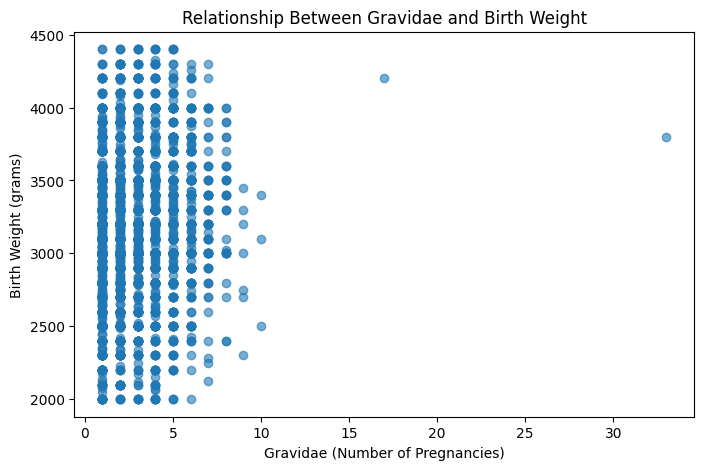

In [87]:
#relationship btn gravedae and birth weight
import matplotlib.pyplot as plt
import seaborn as sns


# Scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(df_filtered["Gravidae"], df_filtered["Birth_weight"], alpha=0.6)

plt.xlabel("Gravidae (Number of Pregnancies)")
plt.ylabel("Birth Weight (grams)")
plt.title("Relationship Between Gravidae and Birth Weight")


plt.show()

DECISION TREE MODELLING

In [88]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [89]:
X = df_filtered[["Gravidae"]]
y = df_filtered["Birth_weight"]

#Splitting innto training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#Decision tree model creation
model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

# Training the model
model.fit(X_train, y_train)

# Telling model to make predictions
y_pred = model.predict(X_test)



***Steve***

In [90]:
#evaluating the decision tree model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 345.0471292066239
Root Mean Squared Error (RMSE): 440.33395429126983
R² Score: 0.023862219691631936


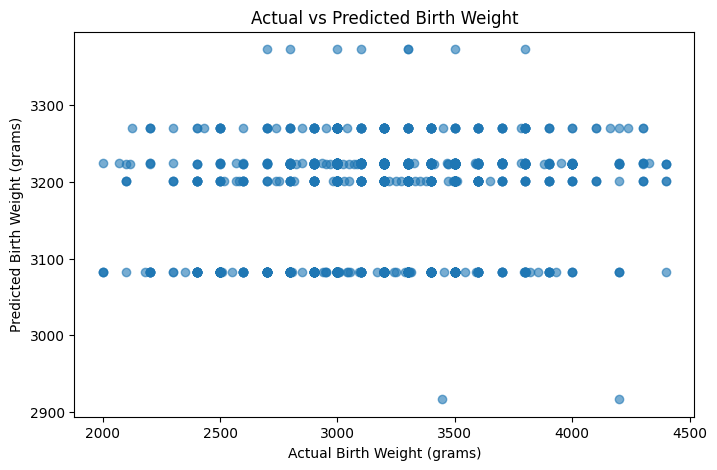

In [91]:
#comparing the actual birth weights with the model's predicted birth weights
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Birth Weight (grams)")
plt.ylabel("Predicted Birth Weight (grams)")
plt.title("Actual vs Predicted Birth Weight")

plt.show()

In [92]:
# Select gravidity and parity-related variable as predictors
X = df_filtered[["Gravidae", "Babies born"]]
y = df_filtered["Birth_weight"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create the Decision Tree Regression model
model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Model training and prediction completed.")

Model training and prediction completed.


In [93]:
# Evaluate the Decision Tree model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 339.5260449492193
Root Mean Squared Error (RMSE): 431.62413715314153
R² Score: 0.06209636801075791


In [94]:
# Model Evaluation Summary

print("Model Evaluation Results")

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

print("\nInterpretation:")
print(f"The model has an average prediction error of approximately {mae:.2f}.")
print(f"The RMSE is {rmse:.2f}, indicating the model's prediction errors.")
print(f"The R² score of {r2:.4f} means the model explains approximately {r2 * 100:.2f}% of the variation in the target variable.")

Model Evaluation Results
Mean Absolute Error (MAE): 339.53
Root Mean Squared Error (RMSE): 431.62
R² Score: 0.0621

Interpretation:
The model has an average prediction error of approximately 339.53.
The RMSE is 431.62, indicating the model's prediction errors.
The R² score of 0.0621 means the model explains approximately 6.21% of the variation in the target variable.


In [95]:
# Low birth weight is defined as birth weight below 2500 grams
df_filtered["Low_Birth_Weight"] = (
    df_filtered["Birth_weight"] < 2500
).astype(int)

# Check the number of infants in each category
print("Low Birth Weight Distribution:")
print(df_filtered["Low_Birth_Weight"].value_counts())

# Check percentages
print("\nPercentage Distribution:")
print(
    df_filtered["Low_Birth_Weight"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Low Birth Weight Distribution:
Low_Birth_Weight
0    5327
1     291
Name: count, dtype: int64

Percentage Distribution:
Low_Birth_Weight
0    94.82
1     5.18
Name: proportion, dtype: float64


Logistic ***Regression***

In [96]:
# LOGISTIC REGRESSION MODEL

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Select predictors
X = df_filtered[["Gravidae", "Babies born"]]

# Select low birth weight as the target
y = df_filtered["Low_Birth_Weight"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create the Logistic Regression model
logistic_model = LogisticRegression(
    class_weight="balanced",
    random_state=42
)

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression training and prediction completed.")

Logistic Regression training and prediction completed.


In [97]:
# Evaluate Logistic Regression Model

accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)

print("Logistic Regression Evaluation")

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Logistic Regression Evaluation
Accuracy: 0.6717
Precision: 0.0919
Recall: 0.6034
F1 Score: 0.1595


In [98]:
# Confusion Matrix for Logistic Regression

cm = confusion_matrix(y_test, y_pred_logistic)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[720 346]
 [ 23  35]]


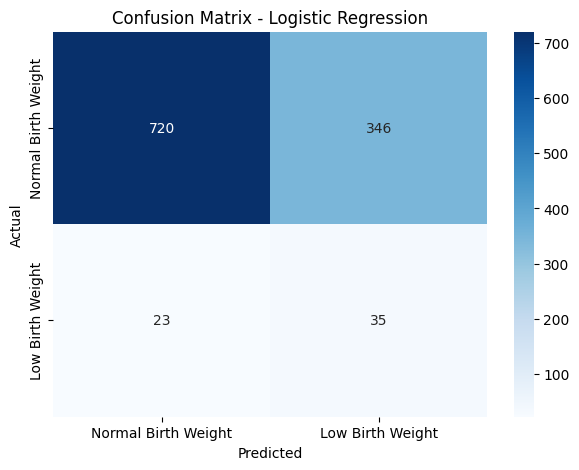

In [99]:
# Visualize the Confusion Matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal Birth Weight", "Low Birth Weight"],
    yticklabels=["Normal Birth Weight", "Low Birth Weight"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [100]:
# Decision Tree Model Results Summary

print("Decision Tree Regression Results")

print(f"MAE: {mae:.2f} grams")
print(f"RMSE: {rmse:.2f} grams")
print(f"R² Score: {r2:.4f}")

Decision Tree Regression Results
MAE: 339.53 grams
RMSE: 431.62 grams
R² Score: 0.0621


In [101]:
# Final Machine Learning Results Summary

print("FINAL MACHINE LEARNING RESULTS")


print("\n1. Decision Tree Regression")

print(f"MAE: {mae:.2f} grams")
print(f"RMSE: {rmse:.2f} grams")
print(f"R² Score: {r2:.4f}")

print("\n2. Logistic Regression")

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

print("\nConclusion:")
print("The Decision Tree Regression model was used to predict actual birth weight,")
print("while Logistic Regression was used to classify low birth weight.")
print("The results suggest that gravidity and parity alone have limited predictive")
print("power for accurately predicting infant birth weight and low birth weight.")

FINAL MACHINE LEARNING RESULTS

1. Decision Tree Regression
MAE: 339.53 grams
RMSE: 431.62 grams
R² Score: 0.0621

2. Logistic Regression
Accuracy: 0.6717
Precision: 0.0919
Recall: 0.6034
F1 Score: 0.1595

Conclusion:
The Decision Tree Regression model was used to predict actual birth weight,
while Logistic Regression was used to classify low birth weight.
The results suggest that gravidity and parity alone have limited predictive
power for accurately predicting infant birth weight and low birth weight.


In [102]:
# Correlation Analysis

correlation_data = df_filtered[
    ["Gravidae", "Babies born", "Birth_weight"]
]

correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,Gravidae,Babies born,Birth_weight
Gravidae,1.00000,0.033620,0.133070
Babies born,0.03362,1.000000,-0.178542
Birth_weight,0.13307,-0.178542,1.000000


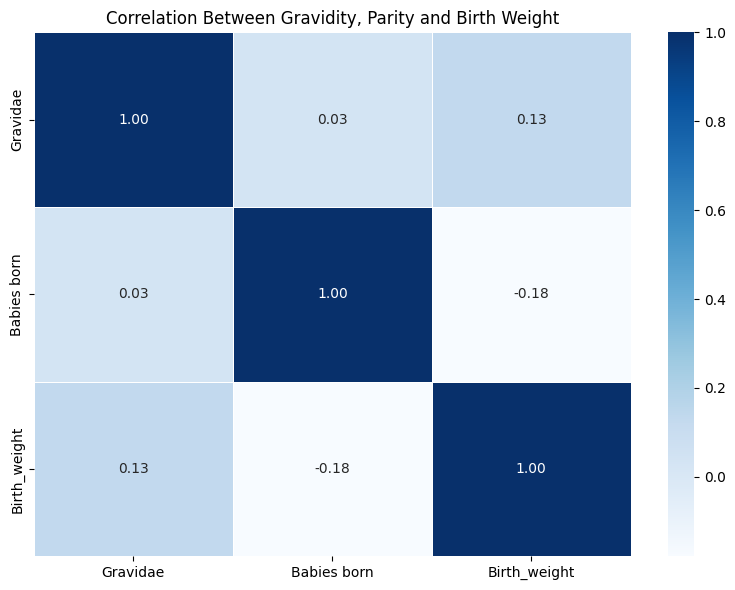

In [103]:
# Correlation Heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Correlation Between Gravidity, Parity and Birth Weight")
plt.tight_layout()
plt.show()

In [106]:
# Pearson Correlation Significance Tests

from scipy.stats import pearsonr

# Gravidity and Birth Weight
gravidae_corr, gravidae_p = pearsonr(
    df_filtered["Gravidae"],
    df_filtered["Birth_weight"]
)

# Parity and Birth Weight
parity_corr, parity_p = pearsonr(
    df_filtered["Babies born"],
    df_filtered["Birth_weight"]
)

print("Pearson Correlation Results")


print("\nGravidae vs Birth Weight")
print(f"Correlation (r): {gravidae_corr:.4f}")
print(f"P-value: {gravidae_p:.4f}")

print("\nParity vs Birth Weight")
print(f"Correlation (r): {parity_corr:.4f}")
print(f"P-value: {parity_p:.4f}")

# Interpretation at 5% significance level
print("\nInterpretation (α = 0.05):")

if gravidae_p < 0.05:
    print("Gravidae and birth weight have a statistically significant relationship.")
else:
    print("Gravidae and birth weight do not have a statistically significant relationship.")

if parity_p < 0.05:
    print("Parity and birth weight have a statistically significant relationship.")
else:
    print("Parity and birth weight do not have a statistically significant relationship.")

Pearson Correlation Results

Gravidae vs Birth Weight
Correlation (r): 0.1331
P-value: 0.0000

Parity vs Birth Weight
Correlation (r): -0.1785
P-value: 0.0000

Interpretation (α = 0.05):
Gravidae and birth weight have a statistically significant relationship.
Parity and birth weight have a statistically significant relationship.


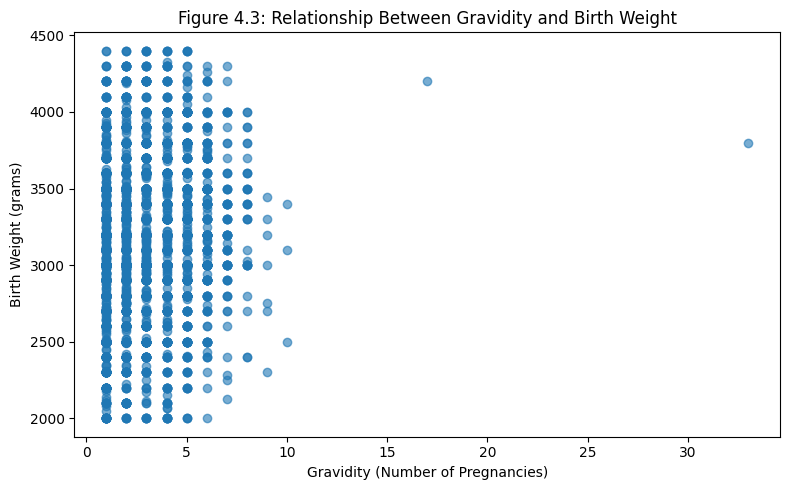

In [107]:
# Gravidity and Birth Weight
plt.figure(figsize=(8, 5))

plt.scatter(
    df_filtered["Gravidae"],
    df_filtered["Birth_weight"],
    alpha=0.6
)

plt.xlabel("Gravidity (Number of Pregnancies)")
plt.ylabel("Birth Weight (grams)")
plt.title("Figure 4.3: Relationship Between Gravidity and Birth Weight")

plt.tight_layout()
plt.show()

In [111]:
# Compare Gravidity and Parity by Low Birth Weight

low_birth_weight_summary = df_filtered.groupby(
    "Low_Birth_Weight"
)[["Gravidae", "Babies born"]].agg(
    ["mean", "median", "count"]
)

print("Gravidity and Parity by Birth Weight Category:")
display(low_birth_weight_summary)

Gravidity and Parity by Birth Weight Category:


Gravidae              Babies born             
                      mean median count        mean median count
Low_Birth_Weight                                                
0                 2.661536    2.0  5327    1.007697    1.0  5327
1                 2.402062    2.0   291    1.120275    1.0   291

In [108]:
# Final Results Summary

results_summary = pd.DataFrame({
    "Analysis": [
        "Gravidae vs Birth Weight",
        "Parity vs Birth Weight",
        "Decision Tree Regression",
        "Logistic Regression"
    ],
    "Result": [
        "r = 0.1331, p < 0.001",
        "r = -0.1785, p < 0.001",
        f"MAE = {mae:.2f}, RMSE = {rmse:.2f}, R² = {r2:.4f}",
        f"Accuracy = {accuracy:.4f}, F1 = {f1:.4f}"
    ]
})
display(results_summary)


,Analysis,Result
0,Gravidae vs Birth Weight,"r = 0.1331, p < 0.001"
1,Parity vs Birth Weight,"r = -0.1785, p < 0.001"
2,Decision Tree Regression,"MAE = 339.53, RMSE = 431.62, R² = 0.0621"
3,Logistic Regression,"Accuracy = 0.6717, F1 = 0.1595"


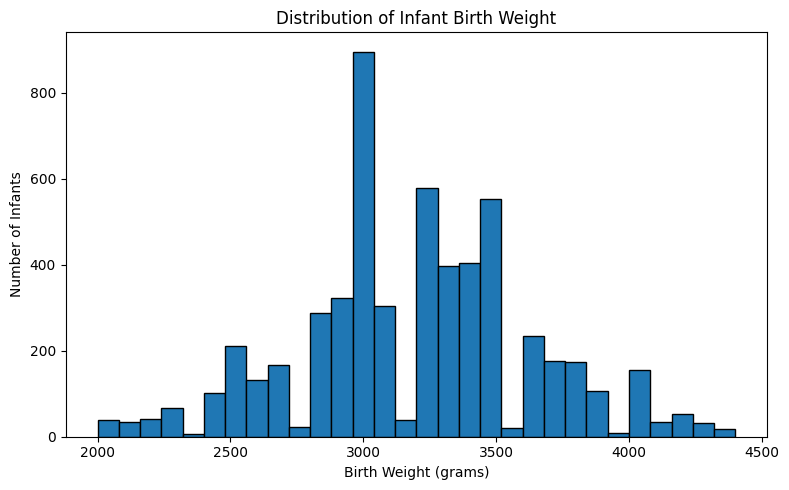

In [109]:
# Birth Weight Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df_filtered["Birth_weight"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Birth Weight (grams)")
plt.ylabel("Number of Infants")
plt.title("Distribution of Infant Birth Weight")

plt.tight_layout()
plt.show()

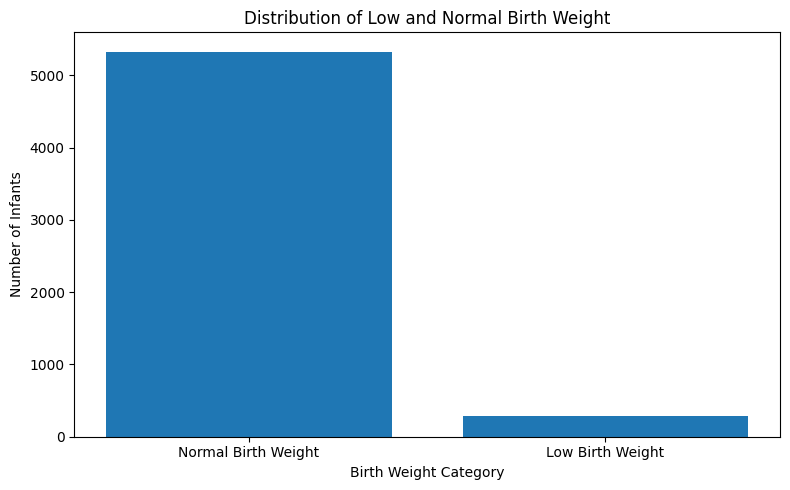

In [110]:
# Low Birth Weight vs Normal Birth Weight

birth_weight_counts = df_filtered["Low_Birth_Weight"].value_counts().sort_index()

labels = ["Normal Birth Weight", "Low Birth Weight"]

plt.figure(figsize=(8, 5))

plt.bar(labels, birth_weight_counts.values)

plt.xlabel("Birth Weight Category")
plt.ylabel("Number of Infants")
plt.title("Distribution of Low and Normal Birth Weight")

plt.tight_layout()
plt.show()

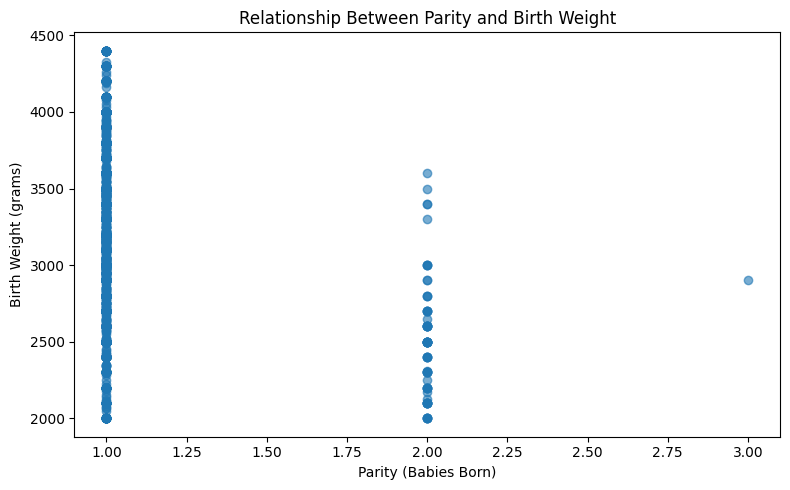

In [112]:
# Relationship Between Parity and Birth Weight

plt.figure(figsize=(8, 5))

plt.scatter(
    df_filtered["Babies born"],
    df_filtered["Birth_weight"],
    alpha=0.6
)

plt.xlabel("Parity (Babies Born)")
plt.ylabel("Birth Weight (grams)")
plt.title("Relationship Between Parity and Birth Weight")

plt.tight_layout()
plt.show()

**Conclusion**

The findings indicate that both gravidity and parity have statistically significant relationships with infant birth weight in Kisumu West Sub County. Gravidity showed a weak positive association with birth weight (r = 0.1331, p < 0.001), while parity showed a weak negative association (r = -0.1785, p < 0.001). Although the relationships were statistically significant, their weak correlation coefficients indicate that gravidity and parity alone have limited influence on variations in birth weight.

The machine learning results support this finding. The Decision Tree Regression model achieved an R² score of 0.0621, with an MAE of 339.53 grams and an RMSE of 431.62 grams, indicating limited predictive ability when using gravidity and parity to predict actual birth weight. The Logistic Regression model for low birth weight achieved an accuracy of 67.17% and an F1 score of 0.1595, indicating weak classification performance.

Overall, the study suggests that gravidity and parity are associated with infant birth weight, but they are not sufficient on their own to accurately predict birth weight or low birth weight. Other maternal, pregnancy, socioeconomic, and clinical factors may contribute to birth-weight outcomes and should be considered in future studies.

In [114]:
from google.colab import files

files.download(
    '/content/Filtered maternity Register - Filtered maternity Register.csv'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>